# Phân tích và phân lớp dữ liệu bệnh tim

Notebook hướng dẫn cách kiểm tra dữ liệu, trực quan hóa, chạy quy trình so sánh mô hình đã triển khai trong `src/heart_disease_classification/train_model.py`, xem kết quả test và kiểm tra artifact đã lưu.

**Lưu ý:** Dự án chỉ nhằm học tập, không phải công cụ chẩn đoán hay khuyến nghị điều trị.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Tìm thư mục gốc dự án dù notebook được mở từ project root hoặc notebooks/.
_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
ROOT = next((p.resolve() for p in _candidates if (p / "src" / "heart_disease_classification" / "train_model.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Không tìm thấy src/heart_disease_classification/train_model.py. Hãy mở notebook trong thư mục dự án.")
sys.path.insert(0, str(ROOT))
from src.heart_disease_classification import train_model as tm
print("Project root:", ROOT)

Project root: /mnt/data/heart_project_work/project


## 1. Đọc dữ liệu và kiểm tra chất lượng

Nhãn gốc `num` từ 0 đến 4 được chuyển thành nhãn nhị phân (`0` nếu `num == 0`, ngược lại `1`). Các giá trị `?` được xử lý như giá trị thiếu.

In [2]:
X, y, raw = tm.load_data()
print(f"Số mẫu: {len(X)} | số thuộc tính đầu vào: {X.shape[1]}")
print("Phân bố nhãn:")
display(y.value_counts().sort_index().rename(index={0: "0 - không ghi nhận", 1: "1 - có ghi nhận"}).to_frame("số mẫu"))
print("Giá trị thiếu theo cột:")
display(X.isna().sum().loc[lambda s: s.gt(0)].to_frame("số thiếu"))
display(X.describe().T.round(2))

Số mẫu: 303 | số thuộc tính đầu vào: 13
Phân bố nhãn:


,số mẫu
target,
0 - không ghi nhận,164
1 - có ghi nhận,139


Giá trị thiếu theo cột:


,số thiếu
ca,4
thal,2


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## 2. Trực quan hóa ban đầu

Biểu đồ cho thấy phân bố nhãn, số giá trị thiếu, phân bố tuổi và tương quan khám phá. Tương quan trên mã số danh mục phải được đọc thận trọng.

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
y.value_counts().sort_index().rename(index={0: "Không ghi nhận bệnh", 1: "Có ghi nhận bệnh"}).plot(kind="bar", ax=ax)
ax.set_title("Phân bố nhãn")
ax.set_ylabel("Số mẫu")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
X.isna().sum().sort_values(ascending=False).head(8).plot(kind="bar", ax=ax)
ax.set_title("Giá trị thiếu theo thuộc tính")
ax.set_ylabel("Số giá trị thiếu")
plt.tight_layout()
plt.show()

/tmp/ipykernel_1451/2728210351.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/tmp/ipykernel_1451/2728210351.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 3. Huấn luyện và chọn thuật toán

Lệnh dưới đây thực hiện tách train/test phân tầng 80/20, đánh giá 8 thuật toán bằng 5-fold cross-validation trên train, chọn theo F1 CV cao nhất, đánh giá trên holdout test, tạo biểu đồ và lưu pipeline đã fit trên toàn bộ dữ liệu để dùng trong app. Chi tiết tiền xử lý và cấu hình nằm trong `src/heart_disease_classification/train_model.py`.

In [4]:
tm.main()

UCI HEART DISEASE - TRAINING COMPLETE
Samples/features: 303/13 | Positive samples: 139 (45.9%)
Missing values: {'ca': 4, 'thal': 2}
Selected model by 5-fold CV F1: Logistic Regression
CV metrics: {'accuracy': 0.8551870748299321, 'precision': 0.8730744935655421, 'recall': 0.8098814229249012, 'f1': 0.8365444245676803, 'roc_auc': 0.9024779568257829}
Holdout test metrics: {'accuracy': 0.8688524590163934, 'precision': 0.8125, 'recall': 0.9285714285714286, 'f1': 0.8666666666666667, 'roc_auc': 0.9664502164502166}
Confusion matrix [[TN, FP], [FN, TP]]: [[27, 6], [2, 26]]
Saved model: /mnt/data/heart_project_work/project/models/heart_disease_pipeline.joblib
Reports: /mnt/data/heart_project_work/project/reports


## 4. Đọc bảng so sánh và metric cuối

Không chọn mô hình theo kết quả test: quy tắc lựa chọn được áp dụng trên cross-validation của tập train. Bảng test chỉ dùng để báo cáo khả năng tổng quát hóa trên holdout này.

In [5]:
comparison = pd.read_csv(ROOT / "reports" / "model_comparison.csv")
display(comparison[["model", "cv_accuracy", "cv_precision", "cv_recall", "cv_f1", "cv_roc_auc", "test_accuracy", "test_recall", "test_f1", "test_roc_auc"]].round(3))
summary = json.loads((ROOT / "reports" / "summary.json").read_text(encoding="utf-8"))
print("Mô hình được chọn:", summary["selected_model"])
print("Metric holdout:")
display(pd.DataFrame([summary["chosen_test_metrics"]]).round(3))
print("Confusion matrix [[TN, FP], [FN, TP]]:", summary["chosen_test_confusion_matrix"])

,model,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,test_accuracy,test_recall,test_f1,test_roc_auc
0,Logistic Regression,0.855,0.873,0.810,0.837,0.902,0.869,0.929,0.867,0.966
1,Extra Trees,0.826,0.809,0.819,0.810,0.904,0.885,0.929,0.881,0.950
2,SVM (RBF),0.822,0.826,0.792,0.805,0.888,0.885,0.964,0.885,0.961
3,K-Nearest Neighbors,0.818,0.827,0.766,0.794,0.872,0.902,0.929,0.897,0.960
4,Random Forest,0.806,0.797,0.783,0.784,0.897,0.885,0.964,0.885,0.951
5,Gradient Boosting,0.798,0.772,0.792,0.781,0.857,0.869,0.929,0.867,0.947
6,Gaussian Naive Bayes,0.744,0.705,0.846,0.749,0.877,0.721,0.893,0.746,0.827
7,Decision Tree,0.694,0.663,0.693,0.675,0.795,0.705,0.857,0.727,0.848


Mô hình được chọn: Logistic Regression
Metric holdout:


,accuracy,precision,recall,f1,roc_auc
0,0.869,0.812,0.929,0.867,0.966


Confusion matrix [[TN, FP], [FN, TP]]: [[27, 6], [2, 26]]


## 5. Xem biểu đồ đánh giá

Confusion matrix cho biết các loại lỗi; ROC curve tổng hợp khả năng phân biệt trên nhiều ngưỡng. Do tập test nhỏ, metric có thể biến động theo cách chia dữ liệu.

algorithm_comparison.png


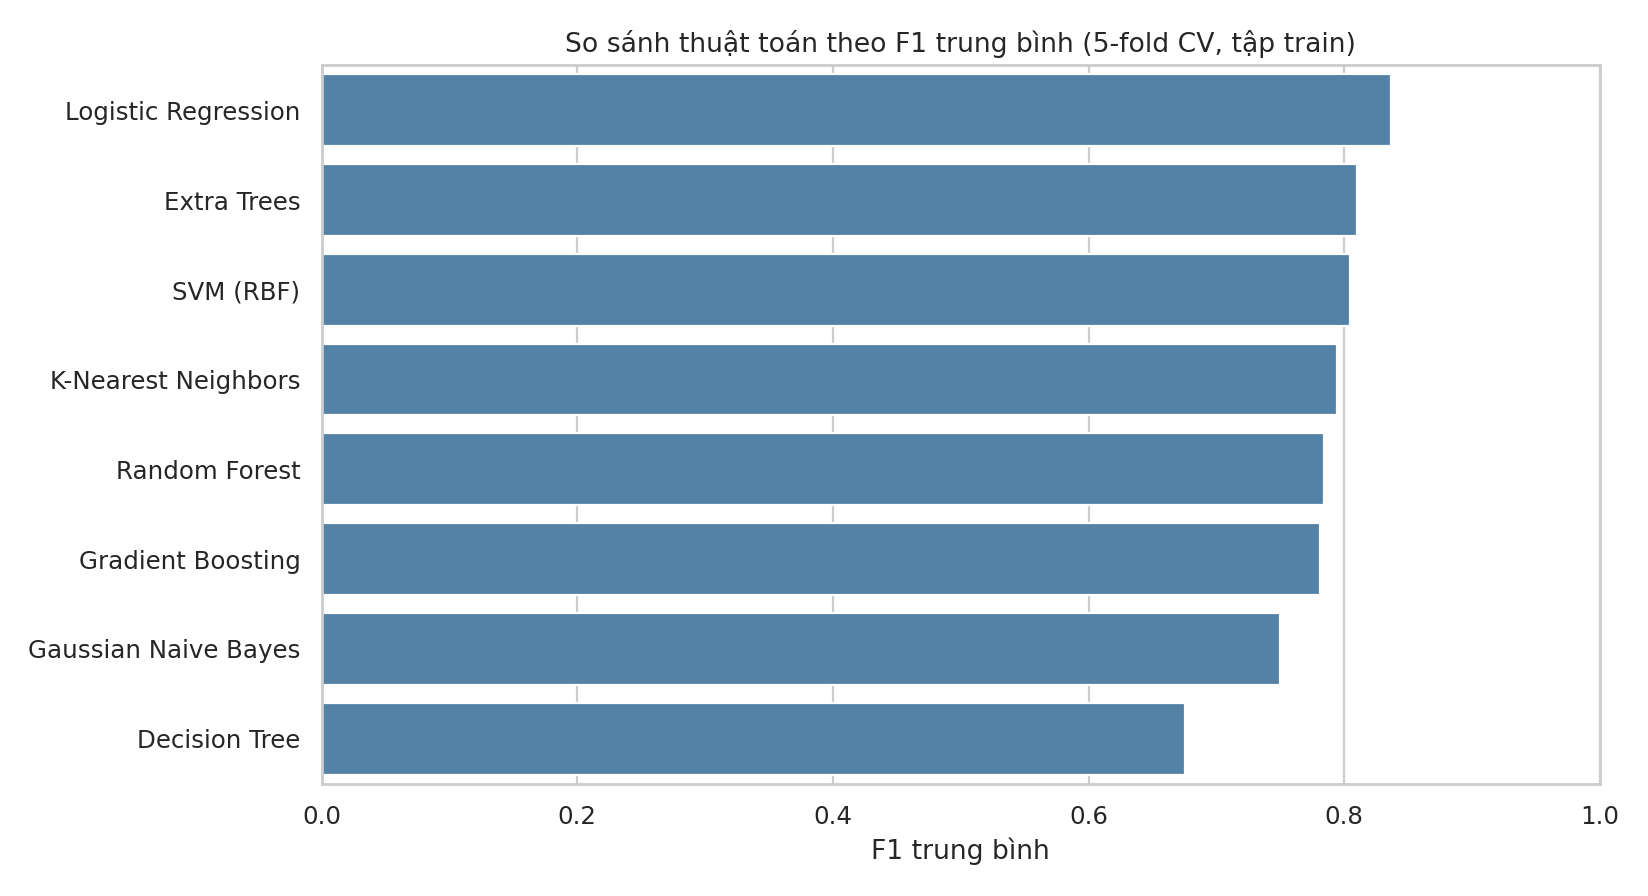

confusion_matrix.png


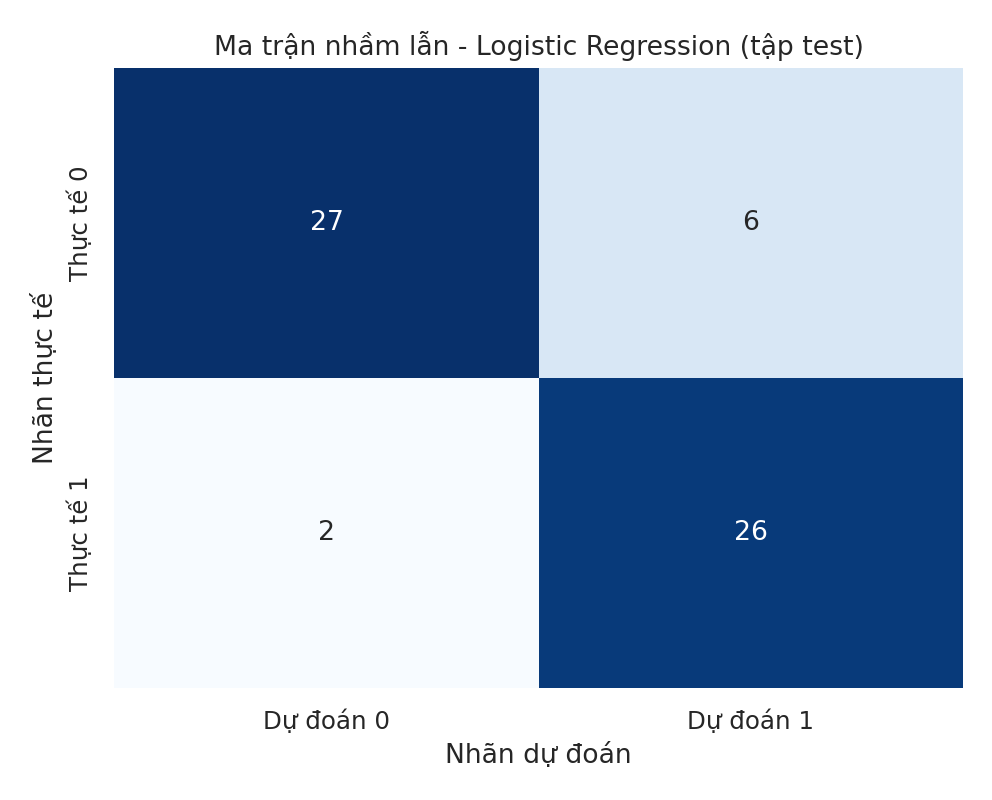

roc_curve.png


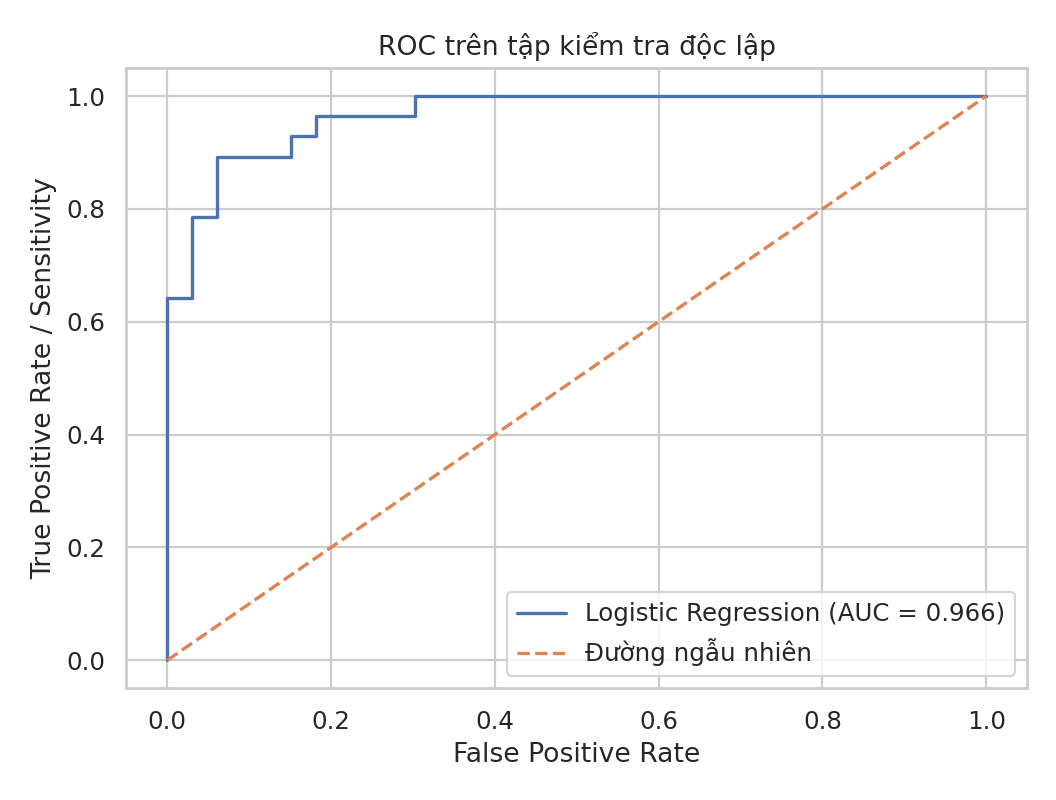

logistic_coefficients.png


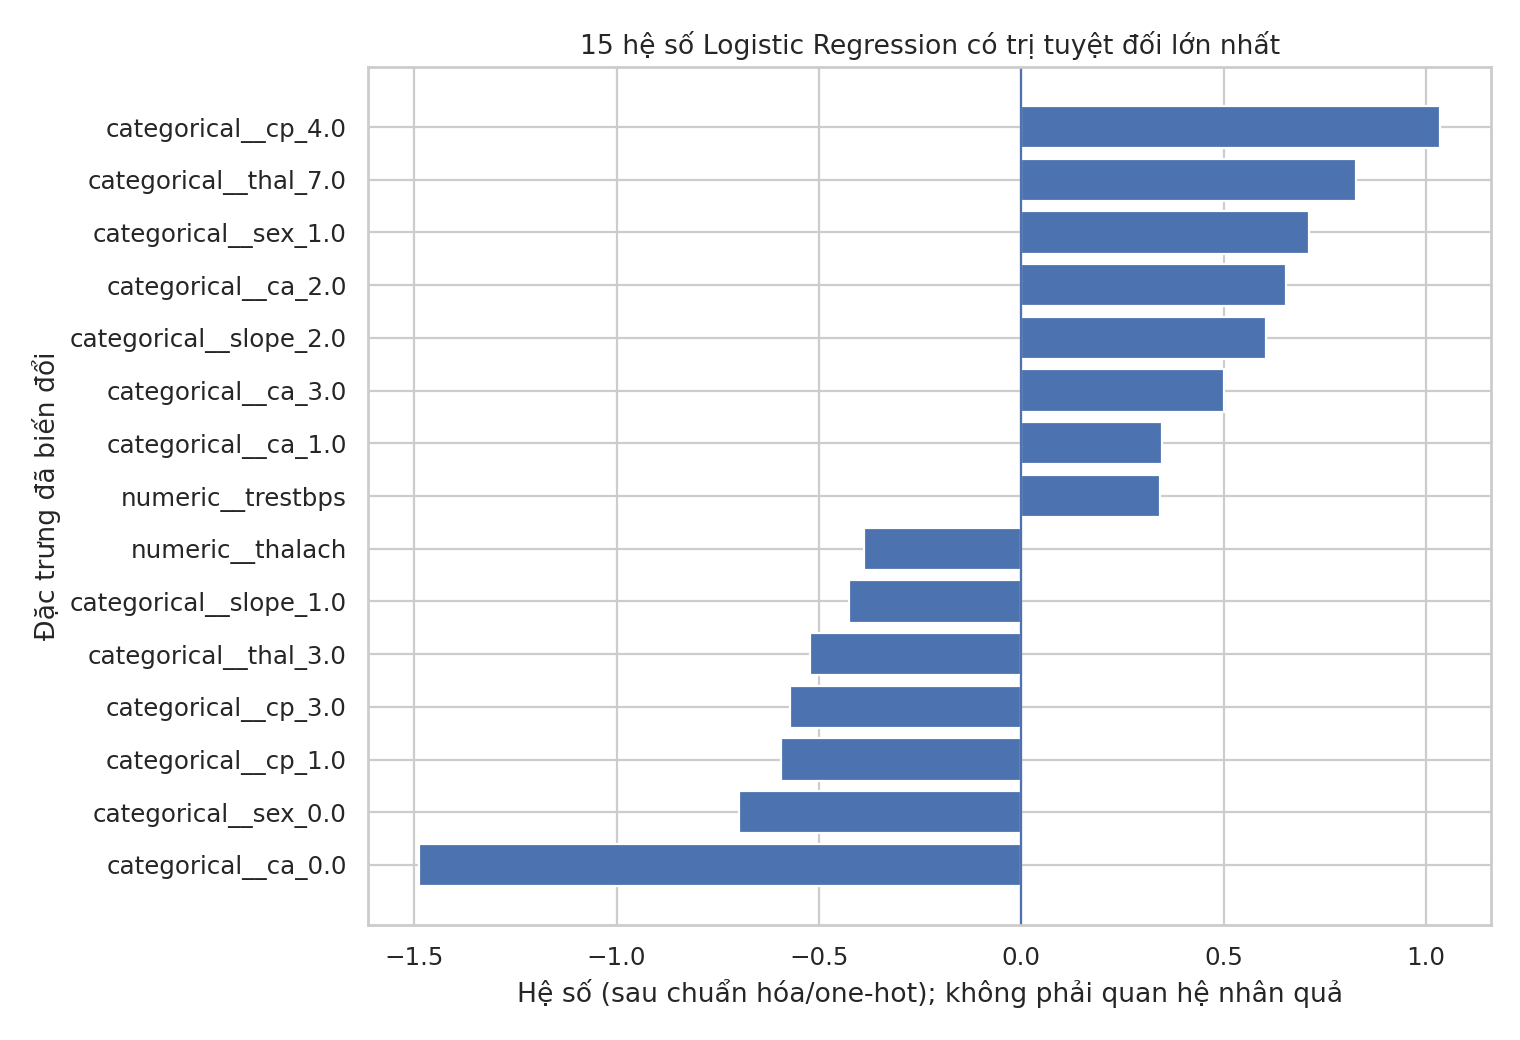

In [6]:
for name in ["algorithm_comparison.png", "confusion_matrix.png", "roc_curve.png", "logistic_coefficients.png"]:
    p = ROOT / "reports" / name
    if p.exists():
        print(name)
        display(Image(filename=str(p)))

## 6. Kiểm tra mô hình đã lưu

Artifact `models/heart_disease_pipeline.joblib` bao gồm tiền xử lý và bộ phân lớp. Nạp file chỉ từ nguồn đáng tin cậy. Điểm `predict_proba` không được hiểu là xác suất mắc bệnh đã hiệu chuẩn lâm sàng.

In [7]:
import joblib
model = joblib.load(ROOT / "models" / "heart_disease_pipeline.joblib")
sample = X.iloc[[0]].copy()
print("Ví dụ này chỉ kiểm tra kỹ thuật gọi predict, không phải trường hợp bệnh nhân thực:")
print("Nhãn do mô hình dự đoán:", int(model.predict(sample)[0]))
print("Điểm mô hình lớp 1:", round(float(model.predict_proba(sample)[0, list(model.classes_).index(1)]), 3))

Ví dụ này chỉ kiểm tra kỹ thuật gọi predict, không phải trường hợp bệnh nhân thực:
Nhãn do mô hình dự đoán: 0
Điểm mô hình lớp 1: 0.171


## 7. Chạy ứng dụng minh họa

Tại thư mục gốc dự án, mở terminal và chạy:

```powershell
pip install -r requirements.txt
streamlit run src/heart_disease_classification/app.py
```

Ứng dụng chỉ phục vụ minh họa học máy và không dùng trong thực hành y khoa.